### Part 1 - Intro to the Problem

Imagine building a recommendation system. Dataset has:
- **100 million users** (samples)
- **10,000 features** per user (browsing history, demographics, preferences, etc.)

Apply OLS: $\boldsymbol{\beta} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$

**But then disaster strikes:**
- Computing $\mathbf{X}^T\mathbf{X}$ requires multiplying a (100M × 10K) matrix by a (10K × 100M) matrix → result is (10K × 10K)
- Inverting a (10K × 10K) matrix has computational complexity of $O(m^3)$ → That's **1 trillion operations**!
- We run out of memory trying to store the intermediate matrices
- Even if it could run, it would take **hours or days** to compute

**The Reality Check:**

OLS is mathematically elegant but computationally impractical for large-scale machine learning. Modern ML deals with:
- Millions or billions of samples
- Thousands or millions of features  
- Need for fast training and frequent updates

**The Solution:**

- What if instead of computing the exact solution directly, we could **iteratively improve** our parameters, taking small steps toward the optimum?
- This is where **Gradient Descent** comes in—trading mathematical exactness for computational efficiency.

**Computational Challenge of OLS**

$$\boldsymbol{\beta}_{\text{OLS}} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$$

Where:
- $\mathbf{X}$ is an $(n \times m)$ matrix ($n$ samples, $m$ features)
- $\mathbf{y}$ is an $(n \times 1)$ vector

**Step-by-step complexity:**

1. **Compute $\mathbf{X}^T\mathbf{X}$:**
   - Matrix multiplication: $(m \times n) \times (n \times m) = (m \times m)$
   - Computational complexity: $O(nm^2)$
   - Memory: Store $(m \times m)$ matrix

2. **Invert $(\mathbf{X}^T\mathbf{X})$:**
   - Matrix inversion: $(m \times m)$ matrix
   - Computational complexity: $O(m^3)$ (using Gaussian elimination)
   - **This is the bottleneck!**

3. **Compute $\mathbf{X}^T\mathbf{y}$:**
   - Matrix-vector multiplication: $(m \times n) \times (n \times 1) = (m \times 1)$
   - Computational complexity: $O(nm)$

4. **Final multiplication:**
   - $(m \times m) \times (m \times 1) = (m \times 1)$
   - Computational complexity: $O(m^2)$

**Total Complexity:** $O(nm^2 + m^3)$


**When does this become problematic?**

| Scenario | $n$ (samples) | $m$ (features) | Dominant Term | Operations | Practical? |
|----------|---------------|----------------|---------------|------------|------------|
| **Small dataset** | 1,000 | 10 | $O(m^3) = 10^3$ | ~1,000 | ✅ Instant |
| **Medium dataset** | 100,000 | 100 | $O(m^3) = 10^6$ | ~1 million | ✅ Fast |
| **Large dataset** | 1,000,000 | 1,000 | $O(m^3) = 10^9$ | ~1 billion | ⚠️ Slow (minutes) |
| **Very large dataset** | 10,000,000 | 10,000 | $O(m^3) = 10^{12}$ | ~1 trillion | ❌ Impractical |
| **Industry scale** | 100,000,000 | 100,000 | $O(m^3) = 10^{15}$ | ~1 quadrillion | ❌ Impossible |

**Memory Issues:**
- Storing $\mathbf{X}^T\mathbf{X}$ requires $m^2$ memory
- For $m = 100,000$ features: $100,000^2 = 10^{10}$ elements × 8 bytes (float64) = **80 GB** just for one matrix!

**The Cubic Curse:**

The $O(m^3)$ matrix inversion means:
- Doubling the number of features → **8× longer computation time**
- 10× more features → **1,000× longer computation time**

This cubic scaling makes OLS prohibitively expensive for modern ML applications with thousands or millions of features.

### Part 2 - Loss Function

- We've seen that OLS computes the exact solution directly but is computationally expensive for large datasets.
- Let's reframe the problem in a way that opens up more efficient solution methods.

**OLS Perspective:**
- Find the coefficients $\boldsymbol{\beta}$ using a closed-form formula
- Requires matrix inversion
- One-shot calculation
- Exact solution

**Optimization Perspective:**
- Define a **loss function** $L(\boldsymbol{\beta})$ that measures prediction error
- Find $\boldsymbol{\beta}$ that **minimizes** this loss function
- Use iterative algorithms
- Approximate solution (but can get arbitrarily close)

**The Key Insight:**

Instead of asking "What is the formula for the optimal $\boldsymbol{\beta}$?", we ask:

> **"How can we systematically improve $\boldsymbol{\beta}$ to reduce prediction error?"**

**direct calculation problem** becomes an **optimization problem**

#### The Loss Function

We need a **loss function** (also called cost function or objective function) that quantifies how "bad" our current parameters are.

For linear regression, we use the **Mean Squared Error (MSE)**:

$$L(\boldsymbol{\beta}) = \text{MSE}(\boldsymbol{\beta}) = \frac{1}{n}\sum_{i=1}^n (y_i - \hat{y}_i)^2 = \frac{1}{n}\sum_{i=1}^n (y_i - \mathbf{x}_i^T\boldsymbol{\beta})^2$$

In matrix notation:

$$L(\boldsymbol{\beta}) = \frac{1}{n}(\mathbf{y} - \mathbf{X}\boldsymbol{\beta})^T(\mathbf{y} - \mathbf{X}\boldsymbol{\beta})$$

**What does this mean?**

- $L(\boldsymbol{\beta})$ measures the average squared difference between predictions and actual values
- **Lower $L(\boldsymbol{\beta})$** → Better predictions → Better model
- **Higher $L(\boldsymbol{\beta})$** → Worse predictions → Worse model

**The Optimization Problem:**

$$\boldsymbol{\beta}^* = \arg\min_{\boldsymbol{\beta}} L(\boldsymbol{\beta})$$

This reads as: "Find the $\boldsymbol{\beta}$ that minimizes the loss function $L$"

**Properties of MSE Loss:**

1. **Non-negative**: $L(\boldsymbol{\beta}) \geq 0$ always
2. **Convex**: Has a single global minimum (no local minima!)
3. **Differentiable**: We can compute gradients everywhere
4. **Smooth**: Gradients change continuously

These properties make MSE an ideal loss function for gradient-based optimization!

#### Gradient Descent?

**Computational Efficiency:**

| Method | Cost per iteration | Memory | Key Limitation |
|--------|-------------------|---------|----------------|
| **OLS** | $O(m^3)$ | $O(m^2)$ | Matrix inversion |
| **Gradient Descent** | $O(nm)$ | $O(m)$ | Needs iteration |

For $n = 1,000,000$ samples and $m = 1,000$ features:
- OLS: ~1 trillion operations (hours/days)
- GD: ~1 billion operations per iteration (seconds)
- Even with 1,000 iterations, GD is **1,000× faster**!

**Key Advantages:**

1. **Scalable**: Works with massive datasets (billions of samples)
2. **Memory efficient**: Stores only parameters, not large matrices
3. **Flexible**: Works with any differentiable loss function
4. **Simple**: No matrix inversion, just follow the gradient

This is why gradient descent (and its variants) are the **foundation of modern machine learning**!

#### What are Gradients

To use gradient descent, we need to understand **gradients**. Let's build from basics:

**Derivatives (1D)**

For a function $f(x)$ of one variable, the derivative tells us the **rate of change**:

$$\frac{df}{dx} = \lim_{h \to 0} \frac{f(x + h) - f(x)}{h}$$

**Example:** $f(x) = x^2$
- Derivative: $\frac{df}{dx} = 2x$
- At $x = 3$: slope is $6$ (positive → function increasing)
- At $x = -2$: slope is $-4$ (negative → function decreasing)
- At $x = 0$: slope is $0$ (flat → minimum!)

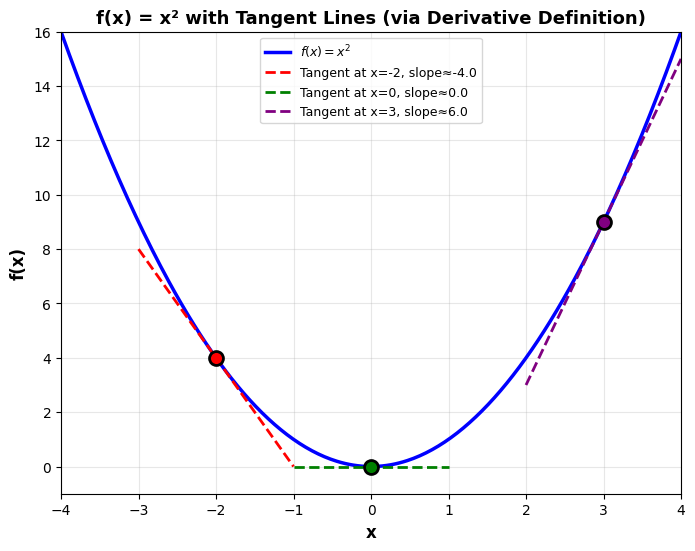

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Function
def f(x):
    return x**2

# Numerical derivative from definition: df/dx ≈ (f(x+h) - f(x)) / h
def numerical_derivative(f, x, h=1e-5):
    return (f(x + h) - f(x)) / h

x = np.linspace(-4, 4, 300)
y = f(x)

# Points where we'll draw tangent lines
points = [-2, 0, 3]
colors = ['red', 'green', 'purple']

plt.figure(figsize=(8, 6))
plt.plot(x, y, 'b-', linewidth=2.5, label=r"$f(x)=x^2$")

# Add tangent lines using numerical derivative
for xi, color in zip(points, colors):
    yi = f(xi)
    slope = numerical_derivative(f, xi)
    tangent_x = np.linspace(xi - 1, xi + 1, 10)
    tangent_y = yi + slope * (tangent_x - xi)

    plt.plot(tangent_x, tangent_y, '--', color=color, linewidth=2,
             label=fr"Tangent at x={xi}, slope≈{slope:.1f}")
    plt.scatter([xi], [yi], color=color, s=100, zorder=5, edgecolors='black', linewidths=2)

plt.xlabel('x', fontsize=12, fontweight='bold')
plt.ylabel('f(x)', fontsize=12, fontweight='bold')
plt.title('f(x) = x² with Tangent Lines (via Derivative Definition)', fontsize=13, fontweight='bold')
plt.legend(fontsize=9)
plt.grid(True, alpha=0.3)
plt.xlim(-4, 4)
plt.ylim(-1, 16)
plt.show()


**Gradients (Multi-Dimensional)**

For a function $f(x, y, z, \dots)$ of several variables, the **gradient** is the vector of all partial derivatives:

$$
\nabla f(x, y, z, \dots) =
\begin{bmatrix}
\dfrac{\partial f}{\partial x} \
\dfrac{\partial f}{\partial y} \
\dfrac{\partial f}{\partial z} \
\vdots
\end{bmatrix}
$$

Each partial derivative tells us **how sensitive** $f$ is to changes in that specific variable while keeping the others constant.



**Key Properties**

1. **Direction:**
   The gradient points in the direction of **steepest ascent** — the fastest increase of $ f $.

2. **Magnitude:**
   Its length shows **how steep** that ascent is.

3. **Zero Gradient:**
   Occurs at a **stationary point** — where $ f $ stops increasing or decreasing(min, max, or saddle point).


**Code Example: Visualizing the Gradient Field**

We’ll numerically compute the gradient for
$$
f(x, y) = x^2 + y^2
$$
and plot its gradient field.


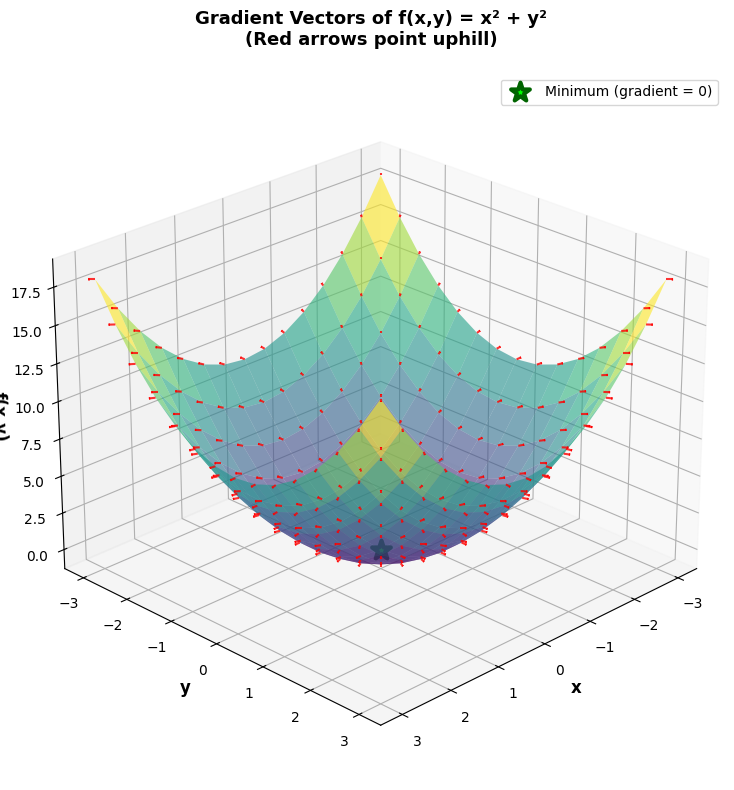

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Create a grid
x = np.linspace(-3, 3, 15)
y = np.linspace(-3, 3, 15)
X, Y = np.meshgrid(x, y)
Z = X**2 + Y**2

# Calculate gradients
dx, dy = 2*X, 2*Y

# Create 3D plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot surface
ax.plot_surface(X, Y, Z, cmap='viridis', alpha=0.6, edgecolor='none')

# Plot gradient vectors (arrows pointing uphill)
ax.quiver(X, Y, Z, dx, dy, np.zeros_like(Z), length=0.1, normalize=True,
          color='red', alpha=0.8, arrow_length_ratio=0.2, linewidths=1.5)

# Mark the minimum
ax.scatter([0], [0], [0], color='lime', s=200, marker='*',
           edgecolors='darkgreen', linewidths=3, label='Minimum (gradient = 0)')

ax.set_xlabel('x', fontsize=12, fontweight='bold')
ax.set_ylabel('y', fontsize=12, fontweight='bold')
ax.set_zlabel('f(x,y)', fontsize=12, fontweight='bold')
ax.set_title('Gradient Vectors of f(x,y) = x² + y²\n(Red arrows point uphill)',
             fontsize=13, fontweight='bold', pad=20)
ax.legend(fontsize=10)
ax.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()

**Interpretation**

* The arrows show the **direction** and **strength** of the gradient at each point.
* The further from the origin, the longer the arrows — meaning the slope is steeper.
* At the origin, the gradient is **zero**, marking the **minimum**.

#### Deriving the Gradient for Linear Regression

**The Loss Function (MSE):**

Recall our loss function:

$$L(\boldsymbol{\beta}) = \frac{1}{n}\sum_{i=1}^n (y_i - \mathbf{x}_i^T\boldsymbol{\beta})^2$$

In matrix form:

$$L(\boldsymbol{\beta}) = \frac{1}{n}(\mathbf{y} - \mathbf{X}\boldsymbol{\beta})^T(\mathbf{y} - \mathbf{X}\boldsymbol{\beta})$$

**Step-by-Step Derivation:**


Expanding:
$$L(\boldsymbol{\beta}) = \frac{1}{n}(\mathbf{y} - \mathbf{X}\boldsymbol{\beta})^T(\mathbf{y} - \mathbf{X}\boldsymbol{\beta})$$

$$= \frac{1}{n}(\mathbf{y}^T\mathbf{y} - \mathbf{y}^T\mathbf{X}\boldsymbol{\beta} - \boldsymbol{\beta}^T\mathbf{X}^T\mathbf{y} + \boldsymbol{\beta}^T\mathbf{X}^T\mathbf{X}\boldsymbol{\beta})$$

Since $\mathbf{y}^T\mathbf{X}\boldsymbol{\beta}$ is a scalar, it equals its transpose: $\mathbf{y}^T\mathbf{X}\boldsymbol{\beta} = \boldsymbol{\beta}^T\mathbf{X}^T\mathbf{y}$

$$L(\boldsymbol{\beta}) = \frac{1}{n}(\mathbf{y}^T\mathbf{y} - 2\boldsymbol{\beta}^T\mathbf{X}^T\mathbf{y} + \boldsymbol{\beta}^T\mathbf{X}^T\mathbf{X}\boldsymbol{\beta})$$

**Taking the Gradient:**

Using matrix calculus rules:
- $\nabla_{\boldsymbol{\beta}}(\boldsymbol{\beta}^T\mathbf{a}) = \mathbf{a}$
- $\nabla_{\boldsymbol{\beta}}(\boldsymbol{\beta}^T\mathbf{A}\boldsymbol{\beta}) = 2\mathbf{A}\boldsymbol{\beta}$ (when $\mathbf{A}$ is symmetric)

$$\nabla L(\boldsymbol{\beta}) = \frac{1}{n}(0 - 2\mathbf{X}^T\mathbf{y} + 2\mathbf{X}^T\mathbf{X}\boldsymbol{\beta})$$

$$= \frac{2}{n}\mathbf{X}^T(\mathbf{X}\boldsymbol{\beta} - \mathbf{y})$$

$$= \frac{2}{n}\mathbf{X}^T\mathbf{e}$$

**The Final Formula:**

$$\boxed{\nabla L(\boldsymbol{\beta}) = \frac{2}{n}\mathbf{X}^T(\mathbf{X}\boldsymbol{\beta} - \mathbf{y})}$$


Now, we have the gradient of our loss function with respect to the parameters $\boldsymbol{\beta}$. This gradient will be used in our gradient descent algorithm.

#### Gradient Descent Algorithm

- Imagine standing on a hillside in thick fog, trying to reach the valley bottom (minimum).
- You can't see far, but you can feel the slope beneath your feet. The strategy is simple:

1. **Feel the slope** (compute gradient)
2. **Take a step downhill** (opposite to gradient direction)
3. **Repeat** until you reach flat ground (minimum)

This is **exactly** what gradient descent does mathematically!

**The Update Rule:**

$$\boldsymbol{\beta}^{(t+1)} = \boldsymbol{\beta}^{(t)} - \alpha \nabla L(\boldsymbol{\beta}^{(t)})$$

Where:
- $\boldsymbol{\beta}^{(t)}$ is the current parameter vector at iteration $t$
- $\nabla L(\boldsymbol{\beta}^{(t)})$ is the gradient at the current position
- $\alpha$ is the learning rate (step size)
- $\boldsymbol{\beta}^{(t+1)}$ is the updated parameter vector


#### Visualizing Gradient Descent: A Simple 1D Example

In [ ]:
# Simple 1D example: minimize f(x) = (x - 3)^2 + 1
def f(x):
    """Function to minimize"""
    return (x - 3)**2 + 1

def gradient_f(x):
    """Gradient (derivative) of f"""
    return 2 * (x - 3)

# Run gradient descent manually
x_start = 8  # Start far from optimum
alpha = 0.3  # Learning rate
iterations = 15

# Track the path
x_path = [x_start]
x = x_start

print("=" * 70)
print("GRADIENT DESCENT: STEP-BY-STEP (1D Example)")
print("=" * 70)
print(f"\nMinimizing f(x) = (x - 3)² + 1")
print(f"Starting at x = {x_start}, Optimum at x = 3\n")
print(f"{'Iteration':<12} {'x':<12} {'f(x)':<12} {'Gradient':<12} {'Step':<12}")
print("-" * 70)

for i in range(iterations):
    fx = f(x)
    grad = gradient_f(x)
    step = -alpha * grad

    print(f"{i:<12} {x:>11.4f} {fx:>11.4f} {grad:>11.4f} {step:>11.4f}")

    # Update x
    x = x - alpha * grad
    x_path.append(x)

print("-" * 70)
print(f"Final x: {x:.6f}, Final f(x): {f(x):.6f}")
print(f"True minimum: x = 3.0, f(3) = 1.0")
print(f"Error: {abs(x - 3):.8f}")

GRADIENT DESCENT: STEP-BY-STEP (1D Example)

Minimizing f(x) = (x - 3)² + 1
Starting at x = 8, Optimum at x = 3

Iteration    x            f(x)         Gradient     Step        
----------------------------------------------------------------------
0                 8.0000     26.0000     10.0000     -3.0000
1                 5.0000      5.0000      4.0000     -1.2000
2                 3.8000      1.6400      1.6000     -0.4800
3                 3.3200      1.1024      0.6400     -0.1920
4                 3.1280      1.0164      0.2560     -0.0768
5                 3.0512      1.0026      0.1024     -0.0307
6                 3.0205      1.0004      0.0410     -0.0123
7                 3.0082      1.0001      0.0164     -0.0049
8                 3.0033      1.0000      0.0066     -0.0020
9                 3.0013      1.0000      0.0026     -0.0008
10                3.0005      1.0000      0.0010     -0.0003
11                3.0002      1.0000      0.0004     -0.0001
12                3

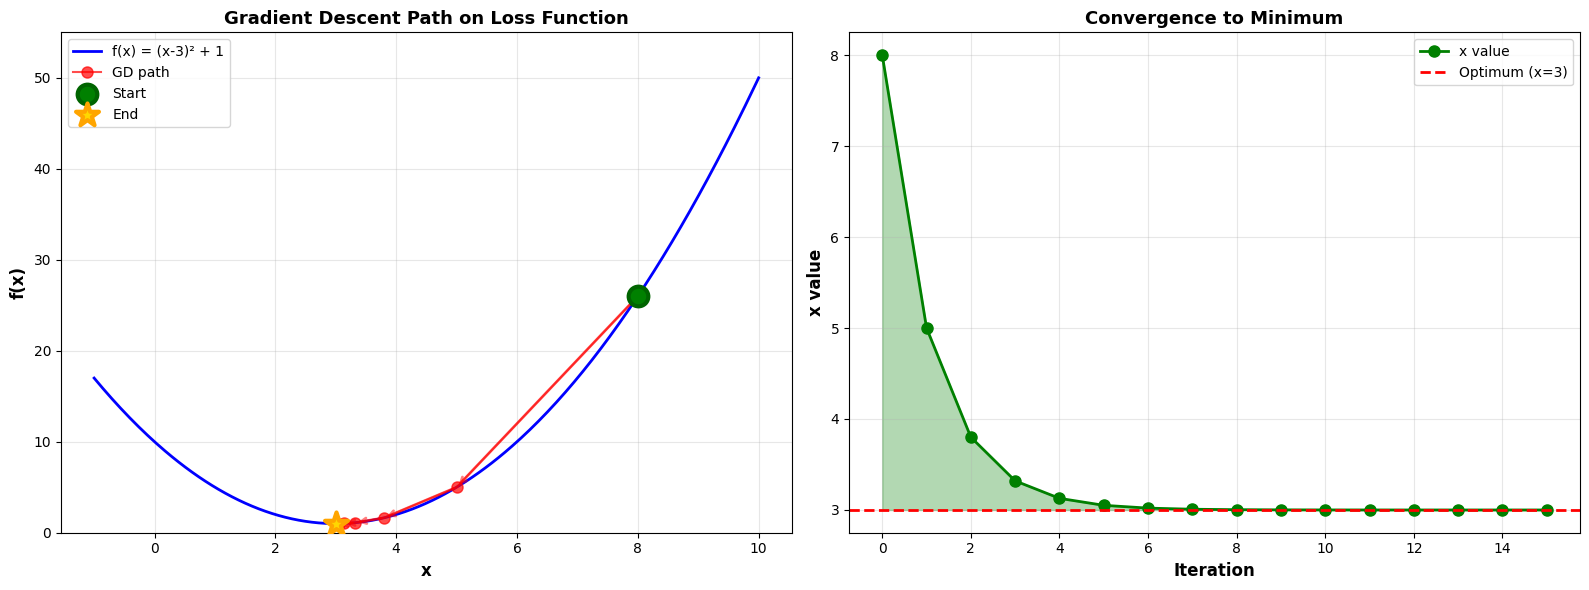

In [ ]:
# Visualize the descent
x_plot = np.linspace(-1, 10, 300)
y_plot = f(x_plot)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Path on function
ax1.plot(x_plot,
         y_plot,
         'b-',
         linewidth=2,
         label='f(x) = (x-3)² + 1')
ax1.plot(x_path,
         [f(x) for x in x_path],
         'ro-',
         markersize=8,
         linewidth=1.5,
         alpha=0.7, label='GD path')

ax1.scatter([x_path[0]],
            [f(x_path[0])],
            s=200,
            marker='o',
            color='green',
            edgecolors='darkgreen',
            linewidths=3,
            zorder=5,
            label='Start')
ax1.scatter([x_path[-1]],
            [f(x_path[-1])],
            s=300,
            marker='*',
            color='gold',
            edgecolors='orange',
            linewidths=3,
            zorder=5,
            label='End')


# Add arrows to show direction
for i in range(min(5, len(x_path)-1)):
    ax1.annotate('',
                 xy=(x_path[i+1],
                 f(x_path[i+1])),
                 xytext=(x_path[i],
                 f(x_path[i])),
                 arrowprops=dict(arrowstyle='->', color='red', lw=2, alpha=0.5))

ax1.set_xlabel('x',
               fontsize=12,
               fontweight='bold')
ax1.set_ylabel('f(x)',
               fontsize=12,
               fontweight='bold')
ax1.set_title('Gradient Descent Path on Loss Function',
              fontsize=13,
              fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0, max(y_plot) + 5)

# Plot 2: Convergence
ax2.plot(range(len(x_path)),
         x_path, 'go-',
         linewidth=2,
         markersize=8,
         label='x value')
ax2.axhline(y=3,
            color='red',
            linestyle='--',
            linewidth=2,
            label='Optimum (x=3)')
ax2.fill_between(range(len(x_path)),
                 x_path,
                 3,
                 alpha=0.3,
                 color='green')
ax2.set_xlabel('Iteration',
               fontsize=12,
               fontweight='bold')
ax2.set_ylabel('x value',
               fontsize=12,
               fontweight='bold')
ax2.set_title('Convergence to Minimum',
              fontsize=13,
              fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**KEY OBSERVATIONS**
- Started at x = 8, far from the minimum at x = 3
- Each step moves in the negative gradient direction (downhill)
- Step size = learning rate × gradient magnitude
- Converges smoothly to the minimum in ~15 iterations
- This is the same principle we'll use for linear regression!

#### Gradient Descent Algorithm

Here's the complete gradient descent algorithm for linear regression:

**Gradient Descent Algorithm:**

```
Input:
  - Training data (X, y)
  - Learning rate α
  - Number of iterations T (or convergence threshold)
  
Initialize:
  - β = random values (or zeros)
  
For t = 1 to T:
  1. Compute predictions: ŷ = Xβ
  2. Compute residuals: e = ŷ - y
  3. Compute gradient: ∇L(β)
  4. Update parameters: β = β - α ∇L(β)
  5. (Optional) Compute and record loss: L(β) = (1/n) ||e||²
  
Output: Optimized parameters β
```

**Stopping Criteria:**

We stop when one of these conditions is met:

1. **Maximum iterations**: Reached predefined number of steps
2. **Convergence**: $|L^{(t)} - L^{(t-1)}| < \epsilon$ (loss not changing much)
3. **Gradient magnitude**: $||\nabla L(\boldsymbol{\beta})|| < \epsilon$ (near critical point)

In practice, we often use a combination of these criteria.

#### Learning Rate

- The **learning rate** $\alpha$ is the most important hyperparameter in gradient descent.
- It controls how big our steps are.

**The Goldilocks Problem:**

- **Too small** ($\alpha \approx 10^{-5}$): Convergence is very slow, may take millions of iterations
- **Too large** ($\alpha \approx 1.0$): May overshoot the minimum, oscillate, or even diverge
- **Just right** ($\alpha \approx 0.001 - 0.1$): Fast and stable convergence

**Choosing Learning Rate:**

1. **Start with a typical value**: Try $\alpha = 0.01$ or $\alpha = 0.001$
2. **Monitor loss**: Loss should decrease monotonically
   - If loss increases → $\alpha$ too large
   - If loss decreases very slowly → $\alpha$ too small
3. **Grid search**: Try values like $[0.0001, 0.001, 0.01, 0.1]$
4. **Learning rate schedules**: Decrease $\alpha$ over time (e.g., $\alpha_t = \frac{\alpha_0}{1 + kt}$)

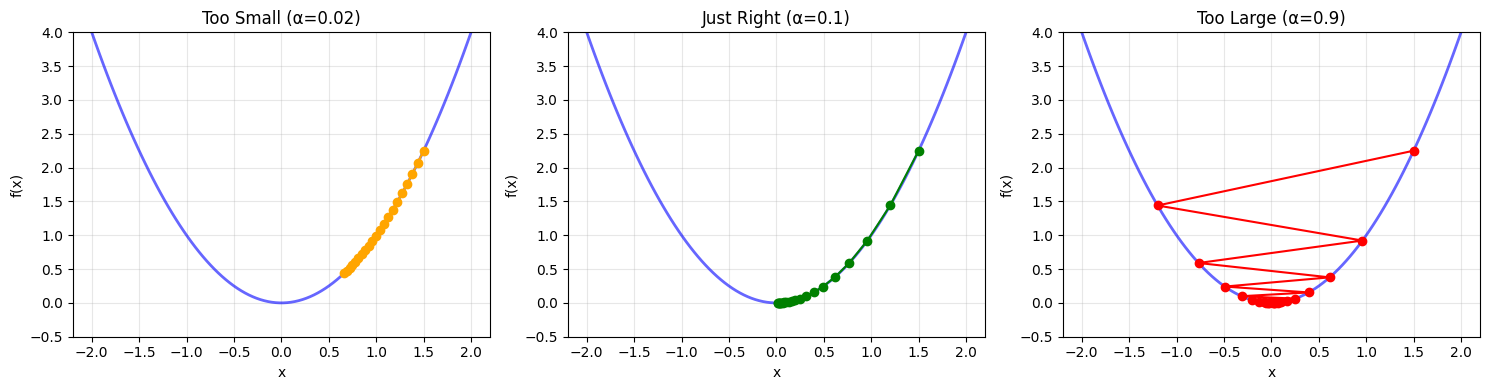

In [ ]:
# Visualize different learning rates
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return x**2

def gd_path(start, lr, iterations):
    x = start
    path = [x]
    for _ in range(iterations):
        x = x - lr * 2 * x
        path.append(x)
    return path

x_range = np.linspace(-2, 2, 100)
y_range = f(x_range)

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
rates = [0.02, 0.1, 0.9]
titles = ['Too Small (α=0.02)', 'Just Right (α=0.1)', 'Too Large (α=0.9)']
colors = ['orange', 'green', 'red']

for i, (rate, title, color) in enumerate(zip(rates, titles, colors)):
    path = gd_path(1.5, rate, 20)

    axs[i].plot(x_range, y_range, 'b-', linewidth=2, alpha=0.6)
    axs[i].plot(path, [f(x) for x in path], 'o-', color=color, markersize=6)
    axs[i].set_xlabel('x')
    axs[i].set_ylabel('f(x)')
    axs[i].set_title(title)
    axs[i].grid(True, alpha=0.3)
    axs[i].set_ylim(-0.5, 4)

plt.tight_layout()
plt.show()

### Part 3 - Gradient Descent for Linear Regression

Let's use the same house price dataset from our previous notebooks. This time, we'll solve it using gradient descent instead of OLS!

#### Training the Model

Now let's train our gradient descent model with properly scaled features:

### Part 4 - Comparing OLS vs Gradient Descent and Summary

Let's verify that gradient descent gives us the same results as OLS from our previous notebook!

**Key Takeaways:**

1. **Why Gradient Descent?**
   - OLS requires matrix inversion: $O(m^3)$ complexity
   - Impractical for large datasets (millions of features)
   - Gradient descent: $O(nm)$ per iteration - scales to massive data!

2. **The Algorithm:**
   - Start with initial parameters
   - Compute gradient of loss function
   - Update parameters: $\beta = \beta - \alpha \nabla L(\beta)$
   - Repeat until convergence

3. **Feature Scaling is Critical:**
   - **Without scaling**: Features with different scales cause gradient descent to fail
   - **With scaling**: All features have mean=0, std=1
   - Result: Smooth convergence to the same optimum as OLS

4. **Learning Rate:**
   - Controls step size in gradient descent
   - Too small → slow convergence
   - Too large → overshooting/divergence
   - Typical values: 0.01 to 0.1 (with scaled features)

**When to Use Each Method:**

| Method | Best For | Limitation |
|--------|----------|------------|
| **OLS** | Small datasets (<10K samples, <1K features) | Matrix inversion $O(m^3)$ |
| **Gradient Descent** | Large datasets (millions of samples/features) | Needs tuning (learning rate) |

In the next notebooks, we'll explore variants like **Stochastic Gradient Descent (SGD)** and **Mini-batch Gradient Descent** that make training even more efficient!